<a href="https://colab.research.google.com/github/JFcamp/rag-flores/blob/main/rag_flores_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌸 Identificador de Flores + RAG sobre Organografia

Projeto que junta **visão computacional** e **RAG** (Retrieval-Augmented Generation), 100% gratuito no Google Colab:

1. **Classificador de imagens**: uma EfficientNet-B0 treinada (fine-tuning) no dataset *tf_flowers* identifica a espécie da flor em uma foto: margarida, dente-de-leão, rosa, girassol ou tulipa.
2. **RAG**: um PDF é dividido em trechos, indexado com embeddings (*multilingual-e5*) e FAISS. As perguntas são respondidas pelo modelo **Qwen2.5-3B-Instruct**, que usa **somente** o conteúdo do PDF e cita as páginas.
3. **Chat multimodal**: você envia a foto, o modelo identifica a flor e você faz perguntas sobre ela.

```
foto ──► EfficientNet ──► "Rosa (97%)"
                              │
pergunta ──► "(Flor: Rosa) pergunta" ──► busca no PDF (e5 + FAISS) ──► páginas ──► Qwen ──► resposta + página
```

### ⚙️ Antes de começar
- **Ambiente de execução → Alterar o tipo de ambiente de execução → T4 GPU**.
- Tenha em mãos o PDF de conhecimento (`guia_organografia_flores.pdf`).
- Rode as células **em ordem**, de cima para baixo. A primeira execução completa leva cerca de 10 minutos.

---
## Parte 0 · Preparação do ambiente

In [ ]:
# 1 · Instalação das bibliotecas e verificação da GPU
!pip install -q -U transformers accelerate sentence-transformers faiss-cpu pypdf

import torch
assert torch.cuda.is_available(), "⚠️ GPU não encontrada: Ambiente de execução → Alterar o tipo → T4 GPU"
print("GPU:", torch.cuda.get_device_name(0))
print("Memória: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 53.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.5/395.5 kB 13.3 MB/s eta 0:00:00
GPU: Tesla T4
Memória: 15.6 GB


In [ ]:
# 2 · Configurações do projeto (ajuste aqui, se quiser)
device = "cuda"

# --- Classificador de imagens ---
DATASET_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
DATA_DIR = "flower_photos"
MODELO_IMG_PATH = "modelo_flores.pt"
IMG_SIZE = 224
BATCH = 32
EPOCAS = 6
LIMIAR_CONFIANCA = 0.60          # abaixo disso, o modelo diz que não tem certeza
NOMES_PT = {"daisy": "Margarida", "dandelion": "Dente-de-leão", "roses": "Rosa",
            "sunflowers": "Girassol", "tulips": "Tulipa"}

# --- RAG ---
EMBEDDER_ID = "intfloat/multilingual-e5-base"
LLM_ID = "Qwen/Qwen2.5-3B-Instruct"
CHUNK_TAMANHO, CHUNK_SOBREPOSICAO = 800, 150
TOP_K_CHUNKS = 6                 # quantos trechos a busca recupera
MAX_PAGINAS = 3                  # quantas páginas inteiras vão para o modelo
MAX_NOVOS_TOKENS = 400

SYSTEM_PROMPT = (
    "Você é um assistente que responde perguntas sobre um documento. "
    "Use SOMENTE as informações dos trechos fornecidos. "
    "Se a resposta não estiver nos trechos, diga exatamente: "
    "\"Não encontrei essa informação no documento.\" "
    "Não invente dados. Responda em português, de forma direta e concisa, "
    "e indique a(s) página(s) de onde tirou a informação, no formato (pág. X)."
)
print("✅ Configurações carregadas.")

✅ Configurações carregadas.


---
## Parte 1 · Classificador de imagens (visão computacional)

Vamos fazer **fine-tuning** de uma EfficientNet-B0 pré-treinada no ImageNet. A rede já sabe reconhecer formas, cores e texturas; trocamos só a última camada para as nossas 5 espécies e ajustamos a rede inteira com taxa de aprendizado baixa.

daisy        → Margarida      633 imagens
dandelion    → Dente-de-leão  898 imagens
roses        → Rosa           641 imagens
sunflowers   → Girassol       699 imagens
tulips       → Tulipa         799 imagens


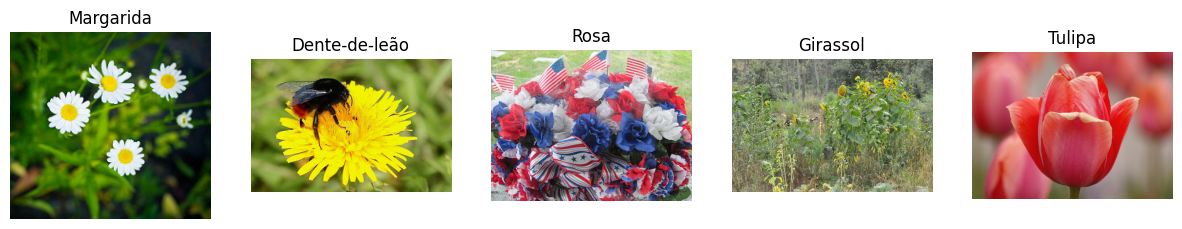

In [ ]:
# 3 · Baixar o dataset tf_flowers e visualizar exemplos
import os, pathlib
import matplotlib.pyplot as plt
from PIL import Image

if not os.path.exists(DATA_DIR):
    !wget -q {DATASET_URL} -O flower_photos.tgz
    !tar -xzf flower_photos.tgz && rm flower_photos.tgz

DATA_PATH = pathlib.Path(DATA_DIR)
classes_pastas = sorted(p.name for p in DATA_PATH.iterdir() if p.is_dir())
for c in classes_pastas:
    print(f"{c:12s} → {NOMES_PT[c]:14s} {len(list((DATA_PATH / c).glob('*.jpg')))} imagens")

fig, axes = plt.subplots(1, len(classes_pastas), figsize=(15, 3))
for ax, c in zip(axes, classes_pastas):
    ax.imshow(Image.open(next((DATA_PATH / c).glob("*.jpg"))))
    ax.set_title(NOMES_PT[c]); ax.axis("off")
plt.show()

In [ ]:
# 4 · Preparar os dados: 80% treino / 20% validação (estratificado) + data augmentation
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # normalização do ImageNet
tf_treino = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
tf_val = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

base_treino = datasets.ImageFolder(DATA_PATH, transform=tf_treino)
base_val    = datasets.ImageFolder(DATA_PATH, transform=tf_val)
CLASSES = base_treino.classes

idx_treino, idx_val = train_test_split(list(range(len(base_treino))), test_size=0.2,
                                       stratify=base_treino.targets, random_state=42)
ds_treino, ds_val = Subset(base_treino, idx_treino), Subset(base_val, idx_val)
dl_treino = DataLoader(ds_treino, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
dl_val    = DataLoader(ds_val,    batch_size=64,    shuffle=False, num_workers=2, pin_memory=True)

print("Classes:", CLASSES)
print(f"Treino: {len(ds_treino)} imagens | Validação: {len(ds_val)} imagens")

Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Treino: 2936 imagens | Validação: 734 imagens


In [ ]:
# 5 · Treinar o modelo (fine-tuning da EfficientNet-B0) — cerca de 3 minutos na T4
import time, torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

def criar_modelo(pretreinado=True):
    m = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretreinado else None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(CLASSES))
    return m.to(device)

def avaliar(modelo, loader):
    modelo.eval(); acertos = total = 0
    with torch.no_grad(), torch.amp.autocast("cuda"):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            acertos += (modelo(x).argmax(1) == y).sum().item(); total += y.size(0)
    return acertos / total

modelo_img = criar_modelo()
criterio = nn.CrossEntropyLoss(label_smoothing=0.1)
otimizador = torch.optim.AdamW(modelo_img.parameters(), lr=3e-4, weight_decay=1e-4)
agendador = torch.optim.lr_scheduler.CosineAnnealingLR(otimizador, T_max=EPOCAS)
scaler = torch.amp.GradScaler("cuda")   # precisão mista: treino mais rápido

melhor_acc = 0.0
for epoca in range(1, EPOCAS + 1):
    modelo_img.train(); t0 = time.time(); perda_total = 0.0
    for x, y in dl_treino:
        x, y = x.to(device), y.to(device)
        otimizador.zero_grad()
        with torch.amp.autocast("cuda"):
            perda = criterio(modelo_img(x), y)
        scaler.scale(perda).backward(); scaler.step(otimizador); scaler.update()
        perda_total += perda.item() * y.size(0)
    agendador.step()

    acc_val = avaliar(modelo_img, dl_val)
    marca = ""
    if acc_val > melhor_acc:
        melhor_acc = acc_val
        torch.save({"state_dict": modelo_img.state_dict(), "classes": CLASSES}, MODELO_IMG_PATH)
        marca = "  💾 salvo"
    print(f"Época {epoca}/{EPOCAS} | perda: {perda_total/len(ds_treino):.4f} "
          f"| acurácia validação: {acc_val:.2%} | {time.time()-t0:.0f}s{marca}")

del otimizador, scaler; torch.cuda.empty_cache()   # libera memória da GPU para o LLM
print(f"\n🏆 Melhor acurácia de validação: {melhor_acc:.2%}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 74.9MB/s]


Época 1/6 | perda: 0.7629 | acurácia validação: 95.23% | 78s  💾 salvo
Época 2/6 | perda: 0.5148 | acurácia validação: 94.96% | 24s
Época 3/6 | perda: 0.4601 | acurácia validação: 95.10% | 24s
Época 4/6 | perda: 0.4451 | acurácia validação: 95.91% | 23s  💾 salvo
Época 5/6 | perda: 0.4335 | acurácia validação: 96.46% | 27s  💾 salvo
Época 6/6 | perda: 0.4234 | acurácia validação: 96.19% | 24s

🏆 Melhor acurácia de validação: 96.46%


               precision    recall  f1-score   support

    Margarida      0.992     0.961     0.976       127
Dente-de-leão      0.973     0.989     0.981       179
         Rosa      0.946     0.953     0.949       128
     Girassol      0.972     0.979     0.975       140
       Tulipa      0.943     0.938     0.940       160

     accuracy                          0.965       734
    macro avg      0.965     0.964     0.964       734
 weighted avg      0.965     0.965     0.965       734



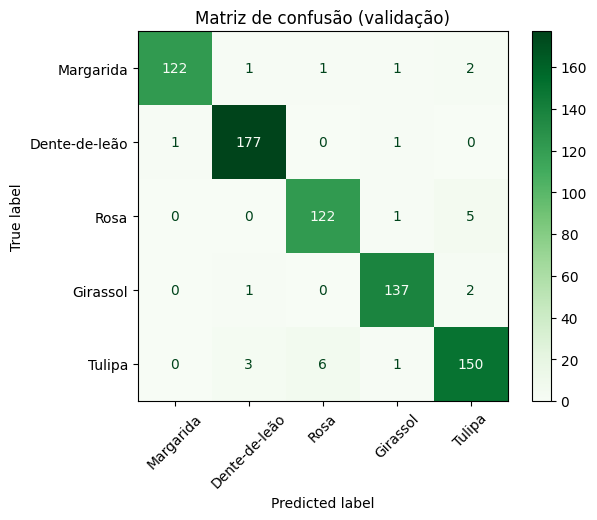

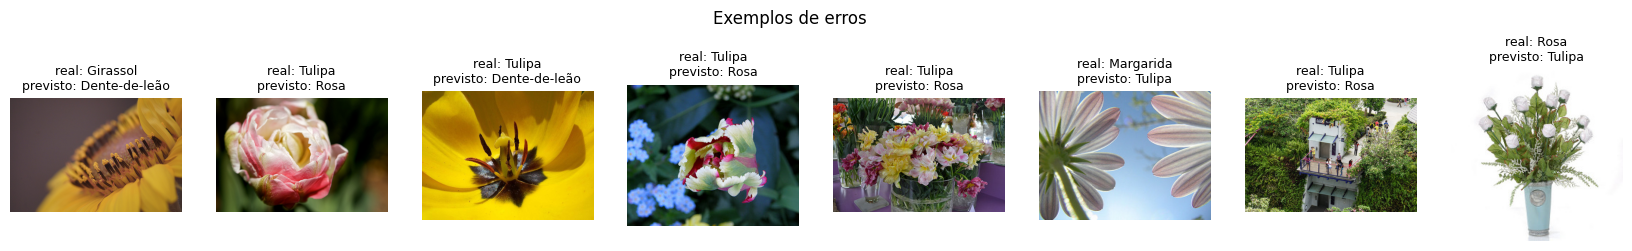

In [ ]:
# 6 · Avaliar o melhor modelo: relatório por classe, matriz de confusão e exemplos de erros
import numpy as np
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

ckpt = torch.load(MODELO_IMG_PATH, map_location=device)
modelo_img.load_state_dict(ckpt["state_dict"]); modelo_img.eval()

y_true, y_pred = [], []
with torch.no_grad(), torch.amp.autocast("cuda"):
    for x, y in dl_val:
        y_pred += modelo_img(x.to(device)).argmax(1).cpu().tolist()
        y_true += y.tolist()

nomes = [NOMES_PT[c] for c in CLASSES]
print(classification_report(y_true, y_pred, target_names=nomes, digits=3))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=nomes,
                                        cmap="Greens", xticks_rotation=45)
plt.title("Matriz de confusão (validação)"); plt.show()

erros = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p][:8]
if erros:
    fig, axes = plt.subplots(1, len(erros), figsize=(2.6 * len(erros), 3))
    for ax, i in zip(np.atleast_1d(axes), erros):
        ax.imshow(Image.open(base_val.samples[idx_val[i]][0])); ax.axis("off")
        ax.set_title(f"real: {nomes[y_true[i]]}\nprevisto: {nomes[y_pred[i]]}", fontsize=9)
    plt.suptitle("Exemplos de erros"); plt.show()

---
## Parte 2 · RAG sobre o PDF

1. O texto do PDF é extraído página por página e dividido em trechos (*chunks*) de ~800 caracteres.
2. Cada trecho vira um vetor (*embedding*) com o modelo **multilingual-e5-base**, e os vetores são guardados em um índice **FAISS**.
3. Na pergunta, a busca encontra os trechos mais parecidos, e o modelo recebe as **páginas inteiras** de onde eles vieram, para não perder o contexto (por exemplo, de qual flor o trecho fala).
4. O **Qwen2.5-3B-Instruct** responde usando somente essas páginas e cita a fonte.

In [ ]:
# 7 · Carregar os modelos de texto (embeddings + LLM) — cerca de 2 minutos na primeira vez
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM

embedder = SentenceTransformer(EMBEDDER_ID, device=device)
tokenizer = AutoTokenizer.from_pretrained(LLM_ID)
llm = AutoModelForCausalLM.from_pretrained(LLM_ID, dtype=torch.float16, device_map=device)
llm.eval()
print(f"✅ Modelos carregados. Memória GPU em uso: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (15 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ Modelos carregados. Memória GPU em uso: 7.4 GB


In [ ]:
# 8 · Funções do RAG: chunking, indexação, busca e resposta em tempo real (streaming)
import re, faiss
from pypdf import PdfReader
from transformers import TextIteratorStreamer
from threading import Thread

def dividir_em_chunks(texto, tamanho=CHUNK_TAMANHO, sobreposicao=CHUNK_SOBREPOSICAO):
    chunks, inicio = [], 0
    while inicio < len(texto):
        fim = min(inicio + tamanho, len(texto))
        if fim < len(texto):   # evita cortar palavras ao meio
            corte = max(texto.rfind(" ", inicio, fim), texto.rfind("\n", inicio, fim))
            if corte > inicio + tamanho // 2:
                fim = corte
        chunks.append(texto[inicio:fim].strip())
        if fim >= len(texto):
            break
        inicio = fim - sobreposicao
    return [c for c in chunks if c]

def processar_pdf(caminho):
    """Extrai o texto, gera os chunks e monta o índice FAISS. Retorna (chunks, index)."""
    global textos_paginas
    chunks, textos_paginas = [], {}
    for i, page in enumerate(PdfReader(caminho).pages, start=1):
        texto = page.extract_text() or ""
        texto = re.sub(r"[ \t]+", " ", texto)
        texto = re.sub(r"\n{3,}", "\n\n", texto).strip()
        textos_paginas[i] = texto
        for c in dividir_em_chunks(texto):
            chunks.append({"id": len(chunks), "pagina": i, "texto": c})
    emb = embedder.encode(["passage: " + c["texto"] for c in chunks], normalize_embeddings=True)
    emb = np.asarray(emb, dtype="float32")
    index = faiss.IndexFlatIP(emb.shape[1])   # produto interno = cosseno (vetores normalizados)
    index.add(emb)
    return chunks, index

def buscar(pergunta, k=TOP_K_CHUNKS):
    q = np.asarray(embedder.encode(["query: " + pergunta], normalize_embeddings=True), dtype="float32")
    scores, ids = index.search(q, k)
    return [{**chunks[i], "score": float(s)} for s, i in zip(scores[0], ids[0])]

def responder_stream(pergunta):
    trechos = buscar(pergunta)
    paginas_top = list(dict.fromkeys(t["pagina"] for t in trechos))[:MAX_PAGINAS]
    contexto = "\n\n".join(f"[Página {p}]\n{textos_paginas[p]}" for p in paginas_top)
    msgs = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"TRECHOS DO DOCUMENTO:\n{contexto}\n\nPERGUNTA: {pergunta}"},
    ]
    entrada = tokenizer.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt",
                                            return_dict=True).to(device)
    streamer = TextIteratorStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True)
    # sem repetition_penalty: ele atrapalharia o modelo a copiar números e nomes do PDF
    Thread(target=llm.generate, kwargs=dict(**entrada, streamer=streamer,
                                            max_new_tokens=MAX_NOVOS_TOKENS, do_sample=False)).start()
    for pedaco in streamer:
        print(pedaco, end="", flush=True)
    print(f"\n   📄 páginas consultadas: {paginas_top}")

print("✅ Funções do RAG prontas.")

✅ Funções do RAG prontas.


In [ ]:
# 9 · Upload e indexação do PDF de conhecimento (ex.: guia_organografia_flores.pdf)
#     Para trocar de PDF, rode esta célula de novo.
from google.colab import files

enviado = files.upload()
pdf_path = list(enviado.keys())[0]
chunks, index = processar_pdf(pdf_path)

paginas_com_texto = len({c["pagina"] for c in chunks})
print(f"✅ {pdf_path}: {len(textos_paginas)} páginas, {paginas_com_texto} com texto, {len(chunks)} chunks indexados.")
if paginas_com_texto == 0:
    print("⚠️ Nenhum texto extraído: o PDF deve ser escaneado (imagem) e precisaria de OCR.")

Saving guia_organografia_flores.pdf to guia_organografia_flores.pdf
✅ guia_organografia_flores.pdf: 25 páginas, 25 com texto, 111 chunks indexados.


---
## Parte 3 · Chat multimodal: foto + perguntas

Comandos do chat:
- **`foto`**: envia uma foto; o modelo identifica a flor e as próximas perguntas passam a ser sobre ela.
- **`limpar`**: esquece a flor identificada (volta a perguntar sobre o PDF em geral).
- **`sair`**: encerra o chat.

Perguntas de exemplo: *"quantos estames ela tem?"*, *"qual a posição do ovário?"*, *"qual a filotaxia?"*, *"qual o tipo de raiz?"*.

In [ ]:
# 10 · Função de identificação da flor pela foto
import torch.nn.functional as F

def identificar_flor():
    """Faz upload de uma foto, classifica e retorna o nome da espécie (ou None)."""
    enviado = files.upload()
    if not enviado:
        return None
    img = Image.open(list(enviado.keys())[0]).convert("RGB")

    modelo_img.eval()
    with torch.no_grad():
        probs = F.softmax(modelo_img(tf_val(img).unsqueeze(0).to(device)).float(), dim=1)[0].cpu()
    top = probs.topk(3)

    plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off")
    plt.title(f"{NOMES_PT[CLASSES[top.indices[0]]]} ({top.values[0]:.0%})"); plt.show()
    for p, i in zip(top.values, top.indices):
        print(f"   {NOMES_PT[CLASSES[i]]:15s} {p:.1%}")

    if top.values[0] < LIMIAR_CONFIANCA:
        print(f"\n⚠️ Não tenho certeza. Talvez não seja uma das espécies que conheço: {', '.join(NOMES_PT.values())}.")
        return None
    especie = NOMES_PT[CLASSES[top.indices[0]]]
    print(f"\n🌸 Flor identificada: {especie}")
    return especie

print("✅ Função de identificação pronta.")

✅ Função de identificação pronta.


📚 Documento: guia_organografia_flores.pdf
Comandos: 'foto' = identificar uma flor | 'limpar' = esquecer a flor | 'sair' = encerrar

❓ Você: qual a cor da rosa
💬 Assistente: A rosa pode apresentar várias cores, conforme mencionado no documento:

"Cores da rosa: branco, rosa, vermelho, amarelo, laranja, roxo e combinações."

Portanto, a resposta é que as rosas podem ser de diversas cores, incluindo branco, rosa, vermelho, amarelo, laranja, roxo e combinações dessas cores. Não encontrei especificamente uma única cor predominante para todas as rosas.
   📄 páginas consultadas: [15, 14, 16]

❓ Você: foto


Saving images (1).jpg to images (1).jpg


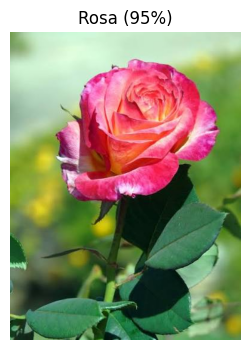

   Rosa            94.9%
   Dente-de-leão   1.9%
   Girassol        1.4%

🌸 Flor identificada: Rosa
❓ Você: qual a cor da rosa
💬 Assistente [Rosa]: A cor da rosa pode variar significativamente, conforme mencionado no trecho da página 16:

"Cores da rosa: branco, rosa, vermelho, amarelo, laranja, roxo e combinações."

Portanto, a resposta é: A cor da rosa pode ser branco, rosa, vermelho, amarelo, laranja, roxo ou combinações dessas cores.
   📄 páginas consultadas: [15, 14, 16]

❓ Você: foto


Saving images.jpg to images.jpg


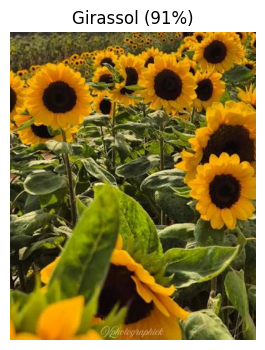

   Girassol        91.3%
   Rosa            2.6%
   Tulipa          2.4%

🌸 Flor identificada: Girassol
❓ Você: qual a nervação da folha de girassol
💬 Assistente [Girassol]: A nervação da folha do girassol é triplinérvea (pág. 18).
   📄 páginas consultadas: [18, 17, 19]

❓ Você: foto


Saving tulipa_645862144.jpg to tulipa_645862144.jpg


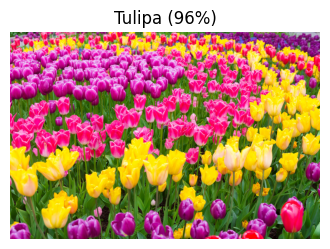

   Tulipa          96.1%
   Dente-de-leão   1.2%
   Rosa            1.0%

🌸 Flor identificada: Tulipa
❓ Você: qual o tipo de caule dela
💬 Assistente [Tulipa]: O tipo de caule da tulipa é subterrâneo, especificamente um bulbo tunicado. (pág. 20)
   📄 páginas consultadas: [20, 21, 4]

❓ Você: foto


Saving images (2).jpg to images (2).jpg


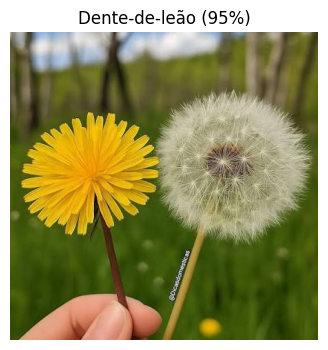

   Dente-de-leão   94.8%
   Tulipa          1.4%
   Margarida       1.4%

🌸 Flor identificada: Dente-de-leão
❓ Você: qual tipo de raiz dele
💬 Assistente [Dente-de-leão]: A raiz do dente-de-leão é pivotante (axial), com uma raiz principal espessa, carnosa e pouco ramificada, castanha por fora e esbranquiçada por dentro. (pág. 11)
   📄 páginas consultadas: [11, 12, 13]

❓ Você: qual a cor dele
💬 Assistente [Dente-de-leão]: A cor da flor do dente-de-leão é amarela (pág. 12).
   📄 páginas consultadas: [12, 11, 13]

❓ Você: qual o tipo de caule
💬 Assistente [Dente-de-leão]: O tipo de caule do dente-de-leão é o seguinte:

- O caule vegetativo é reduzido a uma coroa (cáudice) curtíssima no topo da raiz, com entrenós praticamente nulos, de modo que as folhas formam uma roseta basal.

- A coroa pode se ramificar e formar várias rosetas.
   📄 páginas consultadas: [11, 12, 6]

❓ Você: ele tem folha?
💬 Assistente [Dente-de-leão]: Sim, o dente-de-leão tem folha. Isso está explicitamente mencionado 

Saving unnamed.jpg to unnamed.jpg


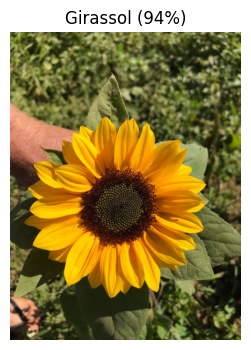

   Girassol        93.6%
   Rosa            1.8%
   Margarida       1.7%

🌸 Flor identificada: Girassol
❓ Você: qual que o tipo de superficie da folha 
💬 Assistente [Girassol]: A superfície da folha do girassol é cartácea, com as duas faces escabrosas (ásperas ao tato), com pelos rígidos de base espessada. (pág. 18)
   📄 páginas consultadas: [18, 17, 3]

❓ Você: sair
👋 Encerrado.


In [ ]:
# 11 · Chat 🌸
especie = None
print(f"📚 Documento: {pdf_path}")
print("Comandos: 'foto' = identificar uma flor | 'limpar' = esquecer a flor | 'sair' = encerrar\n")

while True:
    pergunta = input("❓ Você: ").strip()
    comando = pergunta.lower()
    if comando in ("sair", "exit", "quit"):
        print("👋 Encerrado."); break
    if comando == "foto":
        especie = identificar_flor(); continue
    if comando == "limpar":
        especie = None; print("🧹 Flor esquecida. Perguntas agora são sobre o documento em geral.\n"); continue
    if not pergunta:
        continue
    print(f"💬 Assistente{f' [{especie}]' if especie else ''}: ", end="")
    responder_stream(f"(Flor identificada na foto: {especie}) {pergunta}" if especie else pergunta)
    print()

---
## 🛠️ Dicas e solução de problemas

| Situação | O que fazer |
|---|---|
| O Colab desconectou | Rode tudo de novo (Ambiente de execução → Executar tudo). Arquivos e modelos da sessão são apagados. |
| Erro de memória na GPU (`CUDA out of memory`) | Ambiente de execução → Reiniciar sessão e rodar as células em ordem, uma vez só. |
| Quer trocar de PDF | Rode apenas a célula 9 e depois a 11. |
| Resposta "não encontrei" para algo que está no PDF | Aumente `TOP_K_CHUNKS` ou `MAX_PAGINAS` na célula 2 e rode as células 2, 8 e 11. |
| Foto de flor que não é das 5 espécies | O modelo só conhece 5 classes; se a confiança ficar abaixo de `LIMIAR_CONFIANCA`, ele avisa. |
| Quer guardar o modelo treinado | Baixe o `modelo_flores.pt` (painel de arquivos à esquerda) ou copie para o Google Drive. |